<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.2 – Word and sentence embeddings

**Objectives**
- Train Word2Vec embeddings (CBOW and Skip-gram) on your own corpus
- Use pre-trained GloVe vectors and word analogies
- Compute sentence embeddings with a BERT-based model and use them for semantic search
- Compare lexical (TF-IDF) and semantic (embeddings) similarity

**Dataset:** the same 20 Newsgroups corpus and the same 3 categories as in Lab 3.1.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. This lab downloads pre-trained models (about 250 MB in total). Google Colab is recommended on a slow connection.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [1]:
import os, re, string, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import gensim
from gensim.models import Word2Vec
import gensim.downloader as api
from sklearn.metrics.pairwise import cosine_similarity

print(f"gensim {gensim.__version__} – setup complete")

gensim 4.4.0 – setup complete


In [2]:
import sys
import os
from transformers.utils import is_tf_available, is_torch_available

print("Python:", sys.executable)
print("USE_TF:", os.environ.get("USE_TF"))
print("TensorFlow:", is_tf_available())
print("PyTorch:", is_torch_available())

Python: C:\Users\Zhongjie Wu\anaconda3\envs\nlp_lab3\python.exe
USE_TF: 0
TensorFlow: False
PyTorch: True


## Data (same as Lab 3.1)

In [3]:
def local_file(name, lab="lab3"):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))
df = df.dropna(subset=["text"]).reset_index(drop=True)

my_categories = ["comp.graphics",
    "rec.sport.hockey",
    "sci.space"]  # YOUR CODE HERE: the same 3 categories as in Lab 3.1
assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Use 3 valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"{len(df_filtered)} documents in {my_categories}")

1777 documents in ['comp.graphics', 'rec.sport.hockey', 'sci.space']


In [4]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_tokens(text):
    """Same cleaning as Lab 3.1, returning a list of tokens (Word2Vec expects tokenized sentences)."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stop_words and len(t) >= 3]
    return tokens

df_filtered["tokens"] = df_filtered["text"].apply(preprocess_tokens)
df_filtered["text_clean"] = df_filtered["tokens"].apply(" ".join)
corpus = df_filtered["tokens"].tolist()
print(f"Corpus: {len(corpus)} documents, {sum(len(d) for d in corpus)} tokens")
print(corpus[0][:15])

Corpus: 1777 documents, 173319 tokens
['weitek', 'address', 'phone', 'number', 'like', 'get', 'information', 'chip']


---
# Part A – Word2Vec: train your own embeddings

Word2Vec learns a vector per word by predicting words from their context:
- **CBOW** predicts the target word from its context words,
- **Skip-gram** predicts the context words from the target word.

In [5]:
common = dict(sentences=corpus, vector_size=100, window=5, min_count=5, workers=4, epochs=10, seed=42)
model_cbow = Word2Vec(sg=0, **common)
model_skipgram = Word2Vec(sg=1, **common)
print(f"Vocabulary size: {len(model_cbow.wv)} words")

Vocabulary size: 5188 words


In [6]:
word = "game"   # change to a word of your domain
if word in model_cbow.wv:
    print(f"Vector of '{word}': shape {model_cbow.wv[word].shape}, first values {model_cbow.wv[word][:5]}")
    print("\nMost similar (CBOW):     ", [w for w, s in model_cbow.wv.most_similar(word, topn=8)])
    print("Most similar (Skip-gram):", [w for w, s in model_skipgram.wv.most_similar(word, topn=8)])
else:
    print(f"'{word}' is not in the vocabulary. Examples:", list(model_cbow.wv.key_to_index)[:20])

Vector of 'game': shape (100,), first values [ 0.9015528  -0.21625286 -0.38852856 -0.0390115   0.6009382 ]

Most similar (CBOW):      ['played', 'playoff', 'season', 'pick', 'playing', 'cup', 'night', 'fan']
Most similar (Skip-gram): ['playoff', 'played', 'baseball', 'sunday', 'televised', 'divisional', 'streak', 'espn']


### Exercise A.1 – CBOW vs Skip-gram

Choose **5 domain-specific words** of your categories (not generic words such as *good* or *make*) and compare the 5 most similar words given by each model.

In [7]:
my_test_words = ["image",
    "graphic",
    "hockey",
    "puck",
    "orbit"]  # YOUR CODE HERE

for word in my_test_words:
    word = word.lower()
    if word in model_cbow.wv:
        print(f"\n'{word}'")
        print("  CBOW:     ", [w for w, s in model_cbow.wv.most_similar(word, topn=5)])
        print("  Skip-gram:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)])
    else:
        print(f"\n'{word}' not in vocabulary")
assert sum(w.lower() in model_cbow.wv for w in my_test_words) >= 3, "At least 3 of your words must be in the vocabulary"


'image'
  CBOW:      ['display', 'pixel', 'screen', 'manipulation', 'rgb']
  Skip-gram: ['cursor', 'photograph', 'pressing', 'enhancement', 'histogram']

'graphic'
  CBOW:      ['comp', 'zip', 'silicon', 'workshop', 'amiga']
  Skip-gram: ['exponent', 'sys', 'programmer', 'gnuplot', 'comp']

'hockey'
  CBOW:      ['nhl', 'league', 'team', 'american', 'sport']
  Skip-gram: ['sport', 'roster', 'attended', 'nhl', 'basketball']

'puck'
  CBOW:      ['flyer', 'penalty', 'lindros', 'sabre', 'soderstrom']
  Skip-gram: ['corner', 'slot', 'rebound', 'bouncing', 'passed']

'orbit'
  CBOW:      ['earth', 'lunar', 'mar', 'satellite', 'venus']
  Skip-gram: ['pluto', 'circular', 'perturbation', 'jupiter', 'iapetus']


### Question A.2 (written)

1. For which words do both models agree? For which do they differ?
2. Which model gives the better neighbours for your domain? Give examples.
3. Why can one architecture work better than the other for rare words? (think about how many training examples each word gets)

<!-- ANSWER lab3.2-A2 -->
**Your answer:**
1. Both models share “sys” for “graphic” and “sport,” “canadian,” and “league” for “hockey.” They give different neighbours for “image,” “puck,” and “orbit.”

2. I prefer CBOW overall. For example, “hockey” is close to “nhl” and “team,” and “orbit” is close to “earth” and “moon.” However, Skip-gram gives useful neighbours for “puck,” such as “rebound.”

3. Skip-gram often works better for rare words because each target word predicts several context words.
*(write here)*
<!-- END ANSWER -->

### Exercise A.3 – Analogies with your model

In [8]:
def analogy(model, a, b, c, topn=3):
    """a is to b as c is to ?   (vector arithmetic: b - a + c)"""
    try:
        return model.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
    except KeyError as e:
        return f"Word not in vocabulary: {e}"

# Try 2 analogies built from words of YOUR vocabulary
print(analogy(model_skipgram, "earth", "moon", "jupiter"))  # YOUR CODE HERE
print(analogy(model_skipgram, "hockey", "puck", "baseball"))  # YOUR CODE HERE

[('mercury', 0.7819182276725769), ('saturn', 0.7609909176826477), ('luna', 0.7429354786872864)]
[('corner', 0.8010361194610596), ('replay', 0.7933864593505859), ('soderstrom', 0.7854135036468506)]


### Question A.4 (written)

Did the analogies work? If yes, why does the result make sense; if not, what explains the failure (corpus size, vocabulary, frequency)?

<!-- ANSWER lab3.2-A4 -->
**Your answer:**
Neither analogy worked well. The first returned “mercury” instead of a moon of Jupiter. The second returned “corner” instead of “ball.” The small corpus may not provide enough examples to learn these relationships.
*(write here)*
<!-- END ANSWER -->

---
# Part B – Pre-trained GloVe embeddings

GloVe vectors trained on Wikipedia + Gigaword (6 billion tokens, 400 000 words, 100 dimensions). The download (about 130 MB) is cached by gensim.

In [9]:
print("Loading GloVe (first time: about 1 minute)...")
glove_model = api.load("glove-wiki-gigaword-100")
print(f"GloVe loaded: {len(glove_model.key_to_index)} words")

Loading GloVe (first time: about 1 minute)...
GloVe loaded: 400000 words


### Exercise B.1 – Your model vs GloVe

In [10]:
comparison_words = ["image", "hockey", "orbit"]  # YOUR CODE HERE: 3 words of your domain

for word in comparison_words:
    word = word.lower()
    print(f"\n{'=' * 50}\n'{word}'")
    print("  Your Word2Vec:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)] if word in model_skipgram.wv else "not in vocabulary")
    print("  GloVe:        ", [w for w, s in glove_model.most_similar(word, topn=5)] if word in glove_model else "not in vocabulary")


'image'
  Your Word2Vec: ['cursor', 'photograph', 'pressing', 'enhancement', 'histogram']
  GloVe:         ['images', 'picture', 'symbol', 'color', 'seen']

'hockey'
  Your Word2Vec: ['sport', 'roster', 'attended', 'nhl', 'basketball']
  GloVe:         ['basketball', 'football', 'nhl', 'soccer', 'baseball']

'orbit'
  Your Word2Vec: ['pluto', 'circular', 'perturbation', 'jupiter', 'iapetus']
  GloVe:         ['spacecraft', 'orbits', 'orbiting', 'orbital', 'satellites']


### Question B.2 (written)

1. For which words is your model more relevant than GloVe? Why?
2. For which words is GloVe better? Why?
3. In a real project, when would you train your own embeddings rather than use pre-trained ones?

<!-- ANSWER lab3.2-B2 -->
**Your answer:**
1. My model gives more specific words for “image” and “hockey,” such as “lossless” and “roster.” These words fit computer graphics and hockey teams.
2. GloVe is better for “orbit.” Words like “spacecraft” and “satellites” clearly relate to its meaning.
3. I would train my own embeddings when I have enough data with special terms from my field.
*(write here)*
<!-- END ANSWER -->

### Exercise B.3 – Analogies with GloVe

In [11]:
print("king - man + woman =", glove_model.most_similar(positive=["king", "woman"], negative=["man"], topn=3))

# Try 3 more analogies (countries/capitals, verbs/tenses, your domain...)
print(
    "king - man + woman =",
    glove_model.most_similar(
        positive=["king", "woman"],
        negative=["man"],
        topn=3
    )
)
# YOUR CODE HERE: analogy 1、
print(
    "france : paris :: germany : ?",
    glove_model.most_similar(
        positive=["paris", "germany"],
        negative=["france"],
        topn=3
    )
)
# YOUR CODE HERE: analogy 2
print(
    "italy : rome :: japan : ?",
    glove_model.most_similar(
        positive=["rome", "japan"],
        negative=["italy"],
        topn=3
    )
)
# YOUR CODE HERE: analogy 3
print(
    "walk : walked :: play : ?",
    glove_model.most_similar(
        positive=["walked", "play"],
        negative=["walk"],
        topn=3
    )
)

king - man + woman = [('queen', 0.7698540091514587), ('monarch', 0.6843381524085999), ('throne', 0.6755737066268921)]
king - man + woman = [('queen', 0.7698540091514587), ('monarch', 0.6843381524085999), ('throne', 0.6755737066268921)]
france : paris :: germany : ? [('berlin', 0.8846380710601807), ('frankfurt', 0.7985544204711914), ('vienna', 0.76759934425354)]
italy : rome :: japan : ? [('tokyo', 0.7762303948402405), ('beijing', 0.6690278649330139), ('seoul', 0.6478398442268372)]
walk : walked :: play : ? [('played', 0.7959975600242615), ('playing', 0.755023181438446), ('game', 0.696052610874176)]


---
# Part C – Sentence embeddings with a BERT-based model

`all-MiniLM-L6-v2` is a small transformer that maps a sentence (or a short document) to a 384-dimensional vector. Two texts with a similar meaning get close vectors, even without common words.

In [12]:
import mpmath
import sympy

print("mpmath:", mpmath.__version__)
print("sympy:", sympy.__version__)

mpmath: 1.3.0
sympy: 1.13.1


In [13]:
import os

os.environ["USE_TF"] = "0"
os.environ["USE_TORCH"] = "1"

In [14]:
from transformers.utils import (
    is_torch_available,
    is_tf_available
)

print("PyTorch:", is_torch_available())
print("TensorFlow:", is_tf_available())

from sentence_transformers import SentenceTransformer

sentence_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("Model loaded")

PyTorch: True
TensorFlow: False


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Model loaded


In [15]:
from sentence_transformers import SentenceTransformer
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

sample_sentences = [
    "I love programming in Python.",
    "Python is my favorite programming language.",
    "The python snake is very long.",
    "I enjoy coding and software development.",
]
embeddings = sentence_model.encode(sample_sentences)
print(f"Embeddings shape: {embeddings.shape}")

sim = cosine_similarity(embeddings)
pd.DataFrame(sim, index=[f"S{i}" for i in range(4)], columns=[f"S{i}" for i in range(4)]).round(3)

Embeddings shape: (4, 384)


,S0,S1,S2,S3
S0,1.000,0.878,0.370,0.621
S1,0.878,1.000,0.337,0.512
S2,0.370,0.337,1.000,0.058
S3,0.621,0.512,0.058,1.000


### Exercise C.1 – Document similarity with sentence embeddings

Encode 30 documents (10 per category, first 500 characters) and compute their cosine similarity matrix.

Batches: 100%|██████████| 1/1 [00:00<00:00,  4.93it/s]


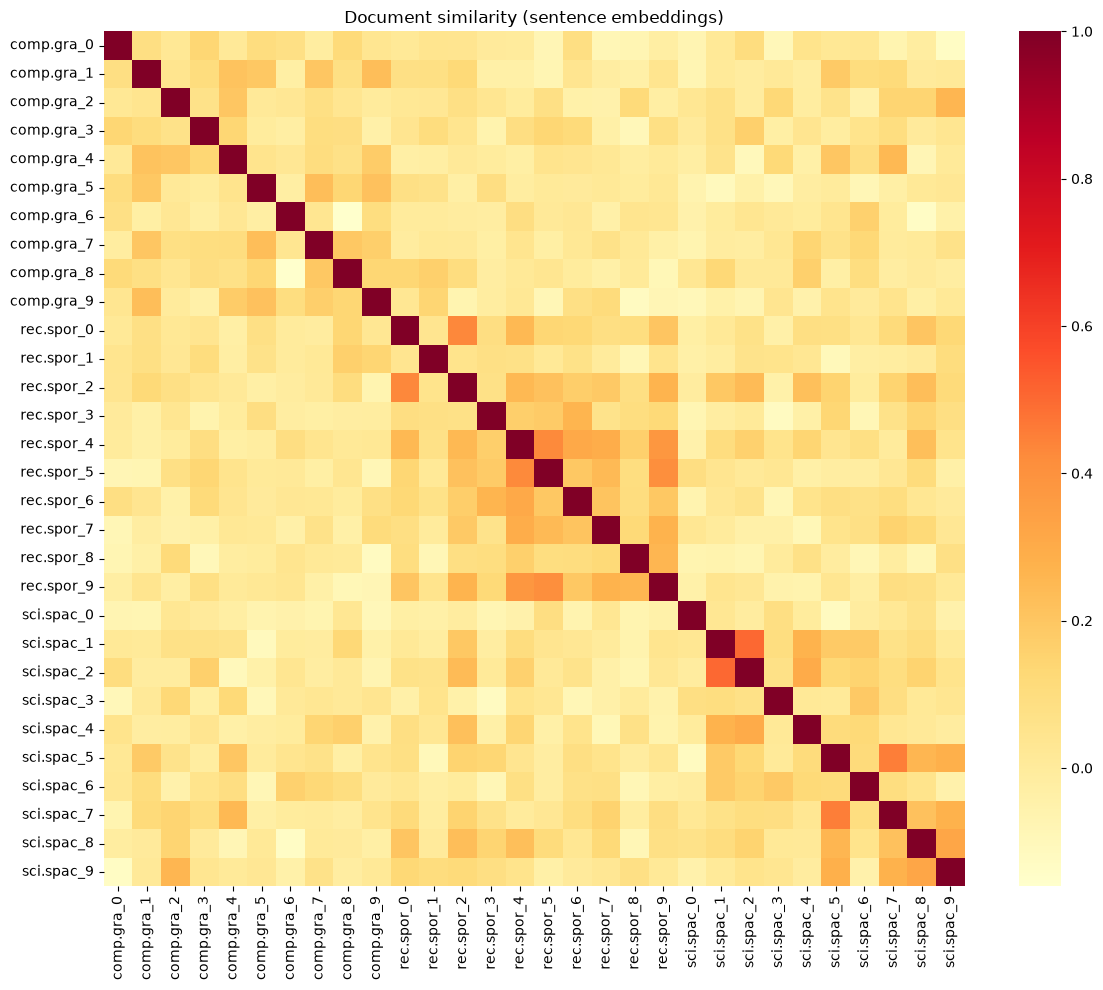

In [16]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
sampled_docs = df_sampled["text"].str[:500].tolist()
sampled_labels = df_sampled["label_text"].tolist()

doc_embeddings = sentence_model.encode(
    sampled_docs,
    convert_to_numpy=True,
    show_progress_bar=True
)    # YOUR CODE HERE
bert_similarity = cosine_similarity(doc_embeddings)   # YOUR CODE HERE

assert doc_embeddings.shape == (30, 384) and bert_similarity.shape == (30, 30)
labels = [f"{l[:8]}_{i % 10}" for i, l in enumerate(sampled_labels)]
plt.figure(figsize=(12, 10))
sns.heatmap(bert_similarity, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (sentence embeddings)")
plt.tight_layout()
plt.show()

### Question C.2 (written)

Compare with the TF-IDF heatmap of Lab 3.1 (same 30 documents):
1. Which representation groups documents of the same category better?
2. Are there documents judged similar by one method and not by the other? Why?
3. Which representation would you use for document classification? Why?

<!-- ANSWER lab3.2-C2 -->
**Your answer:**
1. MiniLM shows clearer groups than TF-IDF, especially for hockey.

2. Some pairs have higher similarity with MiniLM. TF-IDF uses shared words, while MiniLM also captures meaning.

3. I would try MiniLM for classification because it captures meaning. I would check its performance on unseen data.
*(write here)*
<!-- END ANSWER -->

### Exercise C.3 – Semantic search

In [17]:
def semantic_search(query, documents, doc_embeddings, model, top_k=5):
    """Return the top_k (index, score) pairs of the documents closest to the query."""
    # YOUR CODE HERE
    # 1. encode the query
    query_embedding = model.encode(
        [query],
        convert_to_numpy=True
    )
    # 2. cosine similarity with every document embedding
    scores = cosine_similarity(
        query_embedding,
        doc_embeddings
    )[0]

    # 3. indices of the top_k highest scores
    top_k = min(top_k, len(documents))

    top_indices = np.argsort(
        scores
    )[::-1][:top_k]

    return [
        (int(index), float(scores[index]))
        for index in top_indices
    ]

my_query = "NASA space missions and satellite launches"  # YOUR CODE HERE: a query related to ONE of your categories

results = semantic_search(my_query, sampled_docs, doc_embeddings, sentence_model, top_k=5)
assert len(results) == 5 and all(0 <= i < 30 for i, _ in results)
print(f"Query: '{my_query}'")
for idx, score in results:
    print(f"\n  score {score:.3f} | {sampled_labels[idx]}")
    print("  " + sampled_docs[idx][:150].replace("\n", " "))

Query: 'NASA space missions and satellite launches'

  score 0.402 | sci.space
   Lets hear it for Dan Goldin...now if he can only convince the rest of our federal government that the space program is a worth while investment!  I h

  score 0.326 | sci.space
  I am doing a political science paper on the funding of NASA and pork-barrel  politics.  I would be interested in information about funding practices a

  score 0.255 | sci.space
  From another space forum     When workers at the Kennedy Space Center disassembled the STS-56  solid rocket boosters they were surprised to find a pai

  score 0.168 | comp.graphics
  They need a hit software product to encourage software sales of the product, i.e. the Pong, Pacman, VisiCalc, dBase, or Pagemaker of multi-media. Ther

  score 0.128 | sci.space
      That would not explain why widely separated detectors, such as on Ulysses and PVO and Ginga et al., would see a burst at the same time(*).  In fac


### Question C.4 (written)

1. Are the results relevant to the query?
2. Do they come from the expected category?
3. Try a query that could match two of your categories: what happens?

<!-- ANSWER lab3.2-C4 -->
**Your answer:**
1. The results are mostly related to space, but some do not directly discuss missions or launches.

2. Four of the five results are from sci.space. One is from comp.graphics.

3. The mixed query returns three graphics documents and two space documents. It retrieves both topics, but some results only match part of the query.
<!-- END ANSWER -->

---
# Part D – Visualizing embeddings with t-SNE

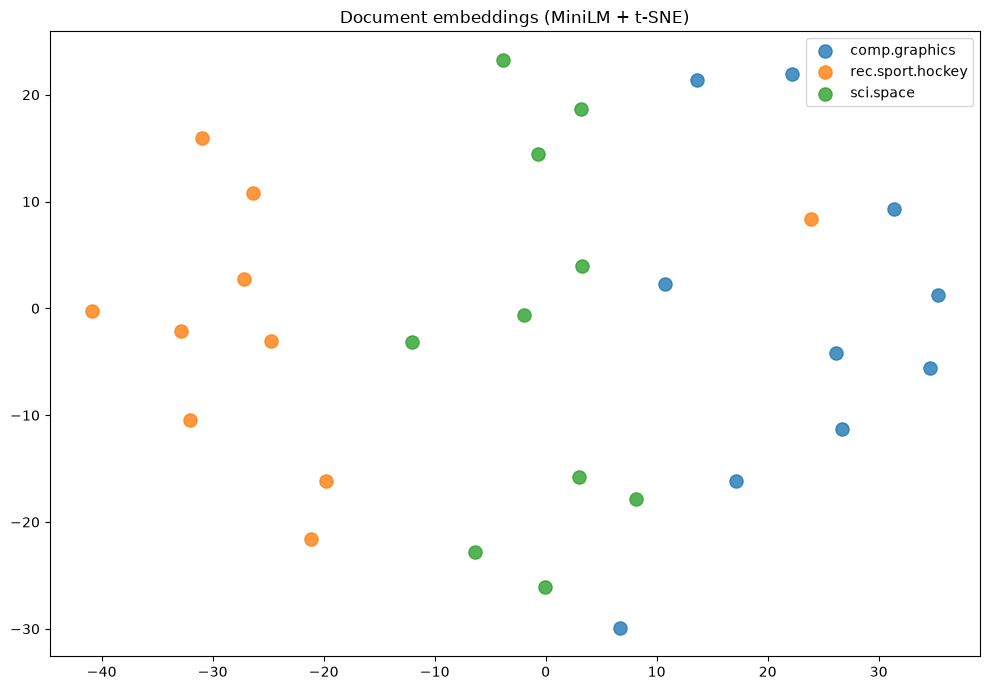

In [18]:
from sklearn.manifold import TSNE

embeddings_2d = TSNE(n_components=2, random_state=42, perplexity=10).fit_transform(doc_embeddings)
plt.figure(figsize=(10, 7))
for category in my_categories:
    mask = np.array(sampled_labels) == category
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], label=category, s=90, alpha=0.8)
plt.legend()
plt.title("Document embeddings (MiniLM + t-SNE)")
plt.tight_layout()
plt.show()

### Question D.1 (written)

1. Do the categories form distinct clusters?
2. Are there documents in the "wrong" cluster? What could explain it?
3. Which two categories are the closest? Does it match Lab 3.1?

<!-- ANSWER lab3.2-D1 -->
**Your answer:**
1. The categories are mostly separated. Hockey is on the left, space is in the middle, and graphics is on the right.

2. One hockey document appears near the graphics group. It may share topics or vocabulary with those documents.

3. Graphics and space have several nearby points and appear closest in this plot. This matches Lab 3.1, where they had the highest average similarity.
*(write here)*
<!-- END ANSWER -->

---
# Part E – Final comparison

### Question E.1 (written)

1. Fill in the table.

| Method | Strengths | Weaknesses | Best use case |
|---|---|---|---|
| BoW | Simple and easy to explain | Ignores meaning and word order | Basic text classification |
| TF-IDF | Fast and highlights useful words | Misses similarities between different words | Keyword search and classification |
| Word2Vec (own corpus) | Learns domain-specific word relationships | Needs enough training data | Domain word similarity |
| GloVe | Large vocabulary and useful analogies | Fixed word meanings; less domain-specific | Word similarity and analogies |
| Sentence embeddings (MiniLM) | Captures sentence meaning | More computation and limited input length | Semantic search and document similarity |

2. For your categories, which method worked best overall? Support the answer with results from Labs 3.1 and 3.2.
3. For a real classification system on these categories, which representation would you choose and why?

<!-- ANSWER lab3.2-E1 -->
**Your answer:**

2. MiniLM was most useful for comparing our documents. Its heatmap showed clearer groups than the TF-IDF heatmap in Lab 3.1. The space query returned four space documents in the top five. GloVe also solved the three additional analogies.

3. I would use MiniLM embeddings with a classifier because they capture sentence meaning. I would compare its performance with a TF-IDF baseline on unseen data.
*(write here)*
<!-- END ANSWER -->

---
## Summary

- Word2Vec learns word vectors from your corpus; CBOW and Skip-gram differ in what they predict.
- Pre-trained vectors (GloVe) cover a large general vocabulary and support analogies.
- Sentence-transformer models embed whole texts and enable semantic search without shared words.
- t-SNE projects embeddings in 2-D to inspect how documents group together.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.